# Phase 3 : Prétraitement et Entraînement des Modèles de Machine Learning
# Bike Sharing Demand Prediction

**Objectif :** Prédire `cnt` (nombre total de locations de vélos par heure) à l'aide de quatre modèles de régression.

Ce notebook fait suite au notebook d'Exploration des Données (EDA) et couvre :
1. Rappel des conclusions de l'EDA
2. Chargement et préparation des données
3. Feature engineering
4. Découpage chronologique train/test
5. Construction de 6 pipelines (4 modèles × différents prétraitements)
6. Entraînement et évaluation
7. Comparaison graphique des résultats

**Modèles utilisés :**
- KNeighborsRegressor (avec StandardScaler et MinMaxScaler)
- ExtraTreesRegressor (sans scaling)
- LinearRegression (avec StandardScaler et MinMaxScaler)
- XGBRegressor (sans scaling)

> ⚠️ `casual` et `registered` ne sont **jamais utilisées** comme features car `cnt = casual + registered` (fuite de données).

---
## 1. Rappel des conclusions de l'EDA

Avant de construire nos modèles, rappelons les conclusions clés de l'EDA :

### Qualité des données
- **0 valeur manquante**, **0 doublon**, **0 incohérence**
- 165 heures absentes (0.9%) correspondant à des heures nocturnes sans location
- `windspeed == 0` pour 12.5% des observations (probablement des valeurs manquantes encodées en 0)

### Distribution de la variable cible `cnt`
- Asymétrie positive forte (skewness = 1.28)
- `log1p(cnt)` réduit l'asymétrie (skewness = -0.82) mais l'inverse
- Les "outliers" (2.9%) sont des valeurs normales aux heures de pointe → **ne pas les supprimer**

### Variables les plus influentes
- **`hr` (heure)** : facteur le plus influent (Spearman = 0.511), profils très différents jour ouvré vs week-end
- **`temp`** : corrélation positive avec `cnt` (Pearson = 0.405)
- **`hum`** : corrélation négative (Pearson = -0.323)
- **`yr`** : tendance croissante 2011→2012 (+64.9%)

### Multicolinéarité
- **`temp` et `atemp` : corrélation = 0.988, VIF ≈ 43** → il faut supprimer `atemp`
- `season` et `mnth` : VIF modéré (3.3-3.5) → acceptable pour les modèles non-linéaires

### Type de jour
- Jours ouvrés : double pic (8h, 17-18h) = trajets domicile-travail
- Week-end/fériés : pic unique en milieu de journée = loisirs

---
## 2. Importation des bibliothèques

Nous importons toutes les bibliothèques nécessaires pour le prétraitement, la modélisation et l'évaluation.

In [25]:
# --- Bibliothèques de base ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# --- Scikit-learn : Prétraitement ---
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

# --- Scikit-learn : Modèles ---
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import LinearRegression

# --- XGBoost ---
from xgboost import XGBRegressor

# --- Scikit-learn : Évaluation ---
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

# --- Configuration visuelle ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
warnings.filterwarnings("ignore")

print("✅ Toutes les bibliothèques sont importées avec succès.")

✅ Toutes les bibliothèques sont importées avec succès.


---
## 3. Chargement des données

Nous chargeons le fichier CSV original `hour.csv` afin de rendre ce notebook **indépendant** du notebook EDA.
Le fichier contient des données horaires de location de vélos sur 2 ans (2011-2012).

In [26]:
# Chargement des données
DATA_PATH = "../hour.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["dteday"])

print(f"Dimensions du dataset : {df.shape}")
print(f"Période couverte : {df['dteday'].min().date()} → {df['dteday'].max().date()}")
df.head()

Dimensions du dataset : (17379, 17)
Période couverte : 2011-01-01 → 2012-12-31


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


---
## 4. Vérification et préparation des données

Nous vérifions que les données correspondent bien aux conclusions de l'EDA :
pas de valeurs manquantes, pas de doublons, et données cohérentes.

In [27]:
# Vérifications rapides
print("=" * 60)
print("VÉRIFICATION DE LA QUALITÉ DES DONNÉES")
print("=" * 60)
print(f"Valeurs manquantes   : {int(df.isna().sum().sum())}")
print(f"Doublons             : {int(df.duplicated().sum())}")
print(f"Doublons (dteday,hr) : {int(df.duplicated(['dteday', 'hr']).sum())}")
print(f"instant croissant    : {df['instant'].is_monotonic_increasing}")
print()

# Vérifier cnt = casual + registered
assert (df["cnt"] == df["casual"] + df["registered"]).all(), "ERREUR : cnt ≠ casual + registered"
print("✅ cnt = casual + registered vérifié")

# Afficher les types
print()
print("Types des variables :")
print(df.dtypes)

VÉRIFICATION DE LA QUALITÉ DES DONNÉES
Valeurs manquantes   : 0
Doublons             : 0
Doublons (dteday,hr) : 0
instant croissant    : True

✅ cnt = casual + registered vérifié

Types des variables :
instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object


<h2>Retour à l'échelle originale des variables</h2>

In [28]:
# Température : [-8, 39] °C
df["temp"] = df["temp"] * (39 - (-8)) + (-8)

# Température ressentie : [-16, 50] °C
df["atemp"] = df["atemp"] * (50 - (-16)) + (-16)

# Humidité : [0, 100] %
df["hum"] = df["hum"] * 100

# Vitesse du vent : [0, 67]
df["windspeed"] = df["windspeed"] * 67

---
## 5. Feature Engineering

L'EDA a montré que :
- L'heure, le mois et le jour de la semaine ont une **nature cyclique** : l'heure 23 est proche de l'heure 0.
- Un encodage numérique simple (0, 1, 2, ...) ne capture pas cette proximité.
- La transformation **sinus/cosinus** permet de représenter cette cyclicité.

### 5.1 Construction du timestamp complet

Le timestamp (`ts`) est nécessaire pour :
1. Le **tri chronologique** des données
2. Le **découpage train/test** respectant l'ordre temporel

In [29]:
# --- Timestamp complet ---
df["ts"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")

# --- Vérification du tri ---
df = df.sort_values("ts").reset_index(drop=True)
print(f"✅ Données triées chronologiquement")
print(f"   Première observation : {df['ts'].iloc[0]}")
print(f"   Dernière observation : {df['ts'].iloc[-1]}")

✅ Données triées chronologiquement
   Première observation : 2011-01-01 00:00:00
   Dernière observation : 2012-12-31 23:00:00


### 5.2 Variables cycliques (sinus/cosinus)

Pour les variables temporelles cycliques (`hr`, `weekday`, `mnth`), nous utilisons l'encodage sinus/cosinus :
$$x_{\sin} = \sin\left(\frac{2\pi \cdot x}{\text{période}}\right), \quad x_{\cos} = \cos\left(\frac{2\pi \cdot x}{\text{période}}\right)$$

**Pourquoi ?** Un encodage entier (0, 1, ..., 23 pour l'heure) crée une discontinuité entre 23h et 0h.
Le sinus/cosinus place ces valeurs proches l'une de l'autre dans un espace 2D continu, ce qui est plus naturel pour les modèles basés sur les distances (KNN) et les modèles linéaires.

✅ Variables cycliques créées : hr_sin, hr_cos, weekday_sin, weekday_cos, mnth_sin, mnth_cos


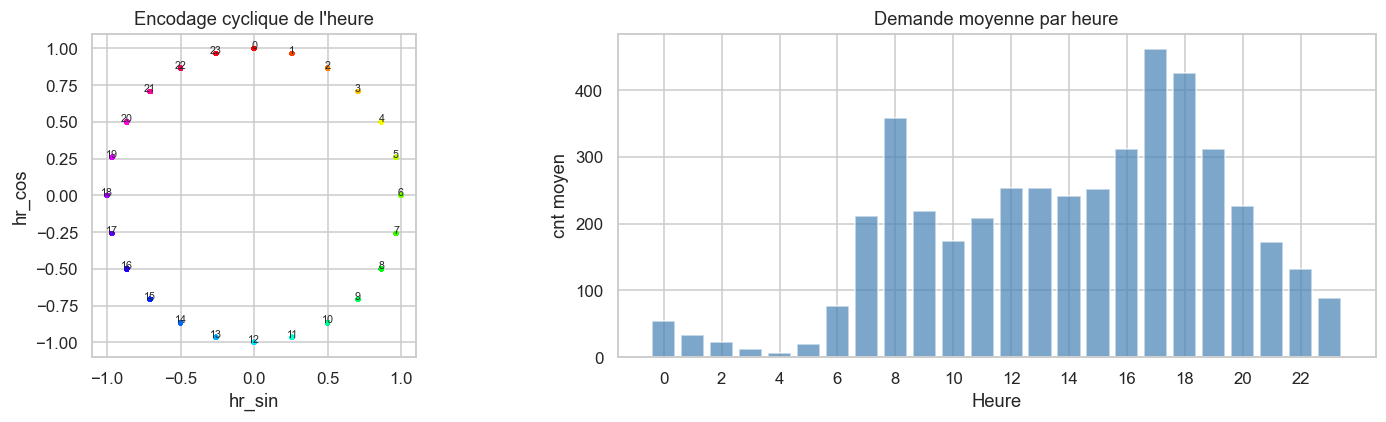

In [30]:
# --- Encodage cyclique ---
def encode_cyclique(series, period):
    """Encode une variable cyclique en sin/cos."""
    angle = 2 * np.pi * series / period
    return np.sin(angle), np.cos(angle)

# Heure (période = 24)
df["hr_sin"], df["hr_cos"] = encode_cyclique(df["hr"], 24)

# Jour de la semaine (période = 7)
df["weekday_sin"], df["weekday_cos"] = encode_cyclique(df["weekday"], 7)

# Mois (période = 12)
df["mnth_sin"], df["mnth_cos"] = encode_cyclique(df["mnth"], 12)

print("✅ Variables cycliques créées : hr_sin, hr_cos, weekday_sin, weekday_cos, mnth_sin, mnth_cos")

# Visualisation de l'encodage cyclique de l'heure
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].scatter(df["hr_sin"], df["hr_cos"], c=df["hr"], cmap="hsv", alpha=0.3, s=5)
axes[0].set_xlabel("hr_sin")
axes[0].set_ylabel("hr_cos")
axes[0].set_title("Encodage cyclique de l'heure")
axes[0].set_aspect("equal")

# Vérifier que les heures proches sont proches dans l'espace 2D
for h in range(24):
    mask = df["hr"] == h
    axes[0].annotate(str(h), (df.loc[mask, "hr_sin"].mean(), df.loc[mask, "hr_cos"].mean()),
                     fontsize=7, ha="center")

# Profil horaire moyen de cnt vs encodage cyclique
hourly_mean = df.groupby("hr")["cnt"].mean()
axes[1].bar(range(24), hourly_mean.values, color="steelblue", alpha=0.7)
axes[1].set_xlabel("Heure")
axes[1].set_ylabel("cnt moyen")
axes[1].set_title("Demande moyenne par heure")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

### 5.3 Analyse de la corrélation entre `temp` et `atemp`

L'EDA a montré que `temp` et `atemp` ont une **corrélation de 0.988** avec un VIF très élevé (~43).
Nous allons vérifier ce résultat et **supprimer `atemp`** pour éviter la multicolinéarité.

Corrélation entre temp et atemp : 0.9877


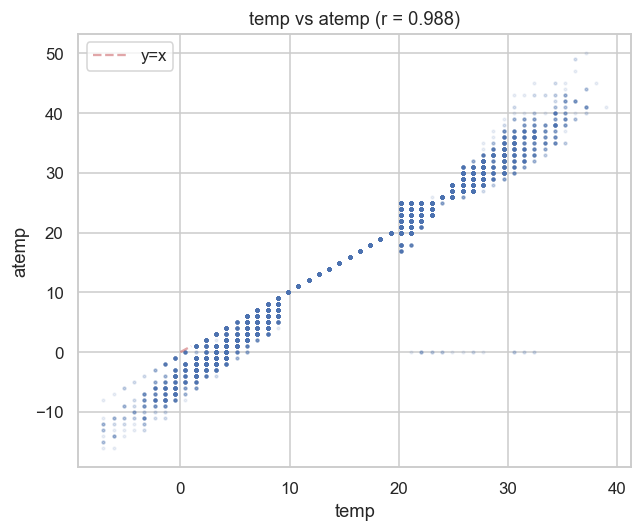


➡️ Conclusion : temp et atemp sont quasi-identiques.
   Nous conservons 'temp' et supprimons 'atemp' pour éviter la multicolinéarité.


In [31]:
# Corrélation entre temp et atemp
corr_temp_atemp = df["temp"].corr(df["atemp"])
print(f"Corrélation entre temp et atemp : {corr_temp_atemp:.4f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df["temp"], df["atemp"], alpha=0.1, s=3)
ax.set_xlabel("temp")
ax.set_ylabel("atemp")
ax.set_title(f"temp vs atemp (r = {corr_temp_atemp:.3f})")
ax.plot([0, 1], [0, 1], "r--", alpha=0.5, label="y=x")
ax.legend()
plt.tight_layout()
plt.show()

print()
print("➡️ Conclusion : temp et atemp sont quasi-identiques.")
print("   Nous conservons 'temp' et supprimons 'atemp' pour éviter la multicolinéarité.")

---
## 6. Définition de X et y

### Stratégie de sélection des features

À partir des conclusions de l'EDA, nous définissons :

**Variables exclues :**
- `instant` : identifiant, pas d'information prédictive
- `dteday` : remplacée par les variables temporelles extraites
- `ts` : utilisé pour le tri uniquement
- `casual` et `registered` : **fuite de données** (cnt = casual + registered)
- `atemp` : quasi-identique à `temp` (corr = 0.988)
- `weather_name` : dérivée de `weathersit` (si elle existait)
- `day_type` : dérivée de `holiday` et `workingday` (si elle existait)

**Variables conservées :**
- **Numériques continues** : `temp`, `hum`, `windspeed`
- **Catégorielles** : `season`, `weathersit`
- **Temporelles cycliques** : `hr_sin`, `hr_cos`, `weekday_sin`, `weekday_cos`, `mnth_sin`, `mnth_cos`
- **Binaires/Ordinales** : `yr`, `holiday`, `workingday`

**Variable cible :** `cnt`

In [32]:
# --- Nettoyage : supprimer les colonnes créées par l'EDA si elles existent ---
cols_to_drop_if_exist = ["weather_name", "day_type"]
for col in cols_to_drop_if_exist:
    if col in df.columns:
        df = df.drop(columns=[col])

# --- Définition des features et de la cible ---
# Variables à exclure
EXCLUDE_COLS = ["instant", "dteday", "ts", "casual", "registered", "cnt", "atemp",
                "hr", "weekday", "mnth"]
# Note : hr, weekday, mnth sont remplacées par leurs versions cycliques (sin/cos)

# Colonnes features
feature_cols = [c for c in df.columns if c not in EXCLUDE_COLS]

# Classification des features
NUMERIC_FEATURES = ["temp", "hum", "windspeed",
                    "hr_sin", "hr_cos", "weekday_sin", "weekday_cos",
                    "mnth_sin", "mnth_cos"]
CATEGORICAL_FEATURES = ["season", "weathersit"]
BINARY_FEATURES = ["yr", "holiday", "workingday"]

print("=" * 60)
print("FEATURES SÉLECTIONNÉES")
print("=" * 60)
print(f"\nNumériques continues ({len(NUMERIC_FEATURES)}) :")
for f in NUMERIC_FEATURES:
    print(f"  • {f}")
print(f"\nCatégorielles ({len(CATEGORICAL_FEATURES)}) :")
for f in CATEGORICAL_FEATURES:
    print(f"  • {f}")
print(f"\nBinaires/Ordinales ({len(BINARY_FEATURES)}) :")
for f in BINARY_FEATURES:
    print(f"  • {f}")

# Construction de X et y
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
X = df[ALL_FEATURES].copy()
y = df["cnt"].copy()

print(f"\n✅ X shape : {X.shape}")
print(f"✅ y shape : {y.shape}")

FEATURES SÉLECTIONNÉES

Numériques continues (9) :
  • temp
  • hum
  • windspeed
  • hr_sin
  • hr_cos
  • weekday_sin
  • weekday_cos
  • mnth_sin
  • mnth_cos

Catégorielles (2) :
  • season
  • weathersit

Binaires/Ordinales (3) :
  • yr
  • holiday
  • workingday

✅ X shape : (17379, 14)
✅ y shape : (17379,)


---
## 7. Découpage des données — Chronologique et Aléatoire

Nous réalisons **deux découpages** afin de comparer leur impact sur les performances :

### Split 1 — Chronologique (recommandé pour les séries temporelles)
- Les **80 % premières observations** servent à l'entraînement.
- Les **20 % dernières** constituent le jeu de test.
- L'ordre temporel est **strictement respecté** : le modèle ne voit jamais le futur.
- C'est la méthode la plus rigoureuse pour des données horaires.

### Split 2 — Aléatoire (référence classique)
- `train_test_split(..., shuffle=True, random_state=42)`
- Les observations sont réparties aléatoirement.
- **Risque de data leakage temporel** : des heures futures peuvent se retrouver
  dans le train, ce qui gonfle artificiellement les performances.
- Inclus ici à titre comparatif pour quantifier cet effet.

In [33]:
from sklearn.model_selection import train_test_split

# ── Split 1 : Chronologique (80 / 20) ─────────────────────────────────────────
split_idx = int(len(X) * 0.8)

X_train_chrono = X.iloc[:split_idx].reset_index(drop=True)
X_test_chrono  = X.iloc[split_idx:].reset_index(drop=True)
y_train_chrono = y.iloc[:split_idx].reset_index(drop=True)
y_test_chrono  = y.iloc[split_idx:].reset_index(drop=True)

# ── Split 2 : Aléatoire (80 / 20, random_state=42) ────────────────────────────
X_train_rand, X_test_rand, y_train_rand, y_test_rand = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

# Réinitialiser les index pour uniformité
X_train_rand = X_train_rand.reset_index(drop=True)
X_test_rand  = X_test_rand.reset_index(drop=True)
y_train_rand = y_train_rand.reset_index(drop=True)
y_test_rand  = y_test_rand.reset_index(drop=True)

# ── Résumé des deux découpages ─────────────────────────────────────────────────
print("=" * 60)
print("DECOUPAGE DES DONNEES")
print("=" * 60)
print(f"  Split chronologique — Train : {len(X_train_chrono):5d}  |  Test : {len(X_test_chrono)}")
print(f"  Split aleatoire     — Train : {len(X_train_rand):5d}  |  Test : {len(X_test_rand)}")
print()
print("  Split chrono : les 80% premieres observations (ordre temporel)")
print("  Split aleat. : tirage aléatoire (risque de data leakage temporel)")

DECOUPAGE DES DONNEES
  Split chronologique — Train : 13903  |  Test : 3476
  Split aleatoire     — Train : 13903  |  Test : 3476

  Split chrono : les 80% premieres observations (ordre temporel)
  Split aleat. : tirage aléatoire (risque de data leakage temporel)


---
## 8. Définition des préprocesseurs

Nous créons un préprocesseur paramétrable via `build_preprocessor(scaler_cls)` :

- **Variables numériques continues** (`temp`, `hum`, `windspeed`) : imputation médiane +
  scaling optionnel (StandardScaler, MinMaxScaler, ou aucun)
- **Variables cycliques** (`hr_sin`, `hr_cos`, `weekday_sin`, `weekday_cos`,
  `mnth_sin`, `mnth_cos`) : imputation médiane seulement (déjà normalisées entre -1 et 1)
- **Variables binaires** (`yr`, `holiday`, `workingday`) : imputation mode, pas de scaling
- **Variables catégorielles ordinales** (`season`, `weathersit`) : OneHotEncoder

Le `ColumnTransformer` assemble tous ces sous-préprocesseurs en un seul objet.

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

# ── Colonnes par type ─────────────────────────────────────────────────────────
NUM_CONT    = ["temp", "hum", "windspeed"]
CYCLIC_COLS = ["hr_sin", "hr_cos", "weekday_sin", "weekday_cos", "mnth_sin", "mnth_cos"]
BINARY_COLS = ["yr", "holiday", "workingday"]
CAT_COLS    = ["season", "weathersit"]

def build_preprocessor(scaler_cls=None):
    """
    Construit un ColumnTransformer adapté à chaque type de variable.
    scaler_cls : StandardScaler, MinMaxScaler, ou None (pas de scaling)
    """
    # Variables numériques continues
    if scaler_cls is not None:
        num_steps = [
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler",  scaler_cls()),
        ]
    else:
        num_steps = [("imputer", SimpleImputer(strategy="median"))]

    num_pipeline     = Pipeline(num_steps)
    cyclic_pipeline  = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    binary_pipeline  = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])
    cat_pipeline     = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe",     OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    preprocessor = ColumnTransformer([
        ("num_cont", num_pipeline,    NUM_CONT),
        ("cyclic",   cyclic_pipeline, CYCLIC_COLS),
        ("binary",   binary_pipeline, BINARY_COLS),
        ("cat",      cat_pipeline,    CAT_COLS),
    ], remainder="drop")

    return preprocessor

print("build_preprocessor() definie.")
print(f"  Num. continues  : {NUM_CONT}")
print(f"  Cycliques       : {CYCLIC_COLS}")
print(f"  Binaires        : {BINARY_COLS}")
print(f"  Catégorielles   : {CAT_COLS}")

build_preprocessor() definie.
  Num. continues  : ['temp', 'hum', 'windspeed']
  Cycliques       : ['hr_sin', 'hr_cos', 'weekday_sin', 'weekday_cos', 'mnth_sin', 'mnth_cos']
  Binaires        : ['yr', 'holiday', 'workingday']
  Catégorielles   : ['season', 'weathersit']


---
## 9. Optimisation des hyperparamètres — Grid Search sur les deux découpages

Chaque modèle est entraîné **deux fois** :
- Une fois sur le split **chronologique** (`TimeSeriesSplit` en CV interne)
- Une fois sur le split **aléatoire** (`KFold` standard en CV interne)

Les **grilles d'hyperparamètres sont identiques** dans les deux cas.
L'objectif est de mesurer l'écart de performance dû au type de découpage.

| Modèle | Méthode GS | CV interne (chrono) | CV interne (aléatoire) |
|--------|-----------|---------------------|------------------------|
| KNN ×2 | `GridSearchCV` | `TimeSeriesSplit(5)` | `KFold(5, shuffle=True)` |
| Extra Trees | `RandomizedSearchCV` (40) | idem | idem |
| LinearRegression ×2 | `GridSearchCV` | idem | idem |
| XGBoost | `RandomizedSearchCV` (50) | idem | idem |

In [35]:
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV,
    TimeSeriesSplit, KFold,
    learning_curve,
)
from sklearn.linear_model import LinearRegression
from scipy.stats import randint as sp_randint, uniform as sp_uniform

RANDOM_STATE = 42

tscv  = TimeSeriesSplit(n_splits=5)          # CV interne pour split chrono
kfcv  = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # CV pour split aléatoire

print("Imports Grid Search OK")
print(f"  CV chrono    : TimeSeriesSplit (n_splits=5)")
print(f"  CV aleatoire : KFold (n_splits=5, shuffle=True)")

Imports Grid Search OK
  CV chrono    : TimeSeriesSplit (n_splits=5)
  CV aleatoire : KFold (n_splits=5, shuffle=True)


### 9.1 Définition des grilles d'hyperparamètres

Les mêmes grilles sont utilisées quel que soit le découpage.

In [36]:
# ── KNN ───────────────────────────────────────────────────────────────────────
knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 10, 15, 20, 30],
    "model__weights"    : ["uniform", "distance"],
    "model__metric"     : ["euclidean", "manhattan"],
}

# ── Extra Trees ───────────────────────────────────────────────────────────────
et_param_dist = {
    "model__n_estimators"    : sp_randint(100, 700),
    "model__max_depth"       : [None, 10, 15, 20, 30],
    "model__min_samples_split": sp_randint(2, 20),
    "model__min_samples_leaf" : sp_randint(1, 10),
    "model__max_features"    : ["sqrt", "log2", 0.5, 0.7, None],
}

# ── LinearRegression ─────────────────────────────────────────────────────────────────────
# LinearRegression n'a pas d'hyperparamètres à optimiser via Grid Search.
# On utilise GridSearchCV avec une grille vide pour conserver la même structure
# de pipeline et de CV interne, garantissant que le scaler est ajusté uniquement
# sur les données d'entraînement de chaque fold.
lr_param_grid = {}

# ── XGBoost ───────────────────────────────────────────────────────────────────
xgb_param_dist = {
    "model__n_estimators"    : sp_randint(100, 700),
    "model__learning_rate"   : sp_uniform(0.01, 0.29),
    "model__max_depth"       : sp_randint(3, 10),
    "model__subsample"       : sp_uniform(0.6, 0.4),
    "model__colsample_bytree": sp_uniform(0.5, 0.5),
    "model__reg_alpha"       : sp_uniform(0.0, 3.0),
    "model__reg_lambda"      : sp_uniform(0.5, 5.0),
    "model__min_child_weight": sp_randint(1, 10),
}

print("Grilles d'hyperparametres definies.")
print(f"  KNN         : {sum(len(v) for v in knn_param_grid.values())} valeurs")
print(f"  Extra Trees : RandomizedSearchCV (40 iters)")
print("  LinearRegression : aucun hyperparamètre (ajustement analytique des MCO)")
print(f"  XGBoost     : RandomizedSearchCV (50 iters)")

Grilles d'hyperparametres definies.
  KNN         : 11 valeurs
  Extra Trees : RandomizedSearchCV (40 iters)
  LinearRegression : aucun hyperparamètre (ajustement analytique des MCO)
  XGBoost     : RandomizedSearchCV (50 iters)


### 9.2 Entraînement par Grid Search — boucle sur les deux découpages

Pour chaque type de split, nous lançons tous les Grid Search avec le CV interne adapté.

In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import ExtraTreesRegressor
from xgboost import XGBRegressor

# Dictionnaire des deux configurations de split
SPLITS = {
    "Chronologique": {
        "X_train": X_train_chrono, "X_test": X_test_chrono,
        "y_train": y_train_chrono, "y_test": y_test_chrono,
        "cv": tscv,
    },
    "Aleatoire": {
        "X_train": X_train_rand, "X_test": X_test_rand,
        "y_train": y_train_rand, "y_test": y_test_rand,
        "cv": kfcv,
    },
}

# Stockage des résultats : {split_name: [liste de résultats]}
results_by_split = {}

for split_name, split_cfg in SPLITS.items():
    X_tr = split_cfg["X_train"]
    X_te = split_cfg["X_test"]
    y_tr = split_cfg["y_train"]
    y_te = split_cfg["y_test"]
    cv   = split_cfg["cv"]

    print("=" * 70)
    print(f"SPLIT : {split_name}  —  Train={len(X_tr)}  Test={len(X_te)}")
    print("=" * 70)

    split_results = []

    # ── KNN (StandardScaler + MinMaxScaler) ───────────────────────────────────
    for scaler_name, scaler_cls in [("StandardScaler", StandardScaler),
                                     ("MinMaxScaler",   MinMaxScaler)]:
        pipe = Pipeline([
            ("preprocessor", build_preprocessor(scaler_cls)),
            ("model", KNeighborsRegressor()),
        ])
        gs = GridSearchCV(pipe, knn_param_grid, cv=cv,
                          scoring="neg_root_mean_squared_error",
                          n_jobs=-1, refit=True, verbose=0)
        gs.fit(X_tr, y_tr)

        y_pred    = gs.best_estimator_.predict(X_te)
        y_pred_tr = gs.best_estimator_.predict(X_tr)
        rmse_cv   = -gs.best_score_
        rmse_test = mean_squared_error(y_te, y_pred) ** 0.5
        rmse_tr   = mean_squared_error(y_tr, y_pred_tr) ** 0.5
        mae_test  = mean_absolute_error(y_te, y_pred)
        r2_test   = r2_score(y_te, y_pred)

        split_results.append(dict(
            Modele="KNN", Scaling=scaler_name,
            RMSE_CV=round(rmse_cv, 2), RMSE_train=round(rmse_tr, 2),
            RMSE=round(rmse_test, 2), MAE=round(mae_test, 2),
            MSE=round(rmse_test**2, 2), R2=round(r2_test, 4),
            y_pred=y_pred, y_pred_train=y_pred_tr,
            estimator=gs.best_estimator_, best_params=gs.best_params_,
        ))
        print(f"  KNN + {scaler_name:15s}  RMSE_CV={rmse_cv:.2f}  "
              f"RMSE_test={rmse_test:.2f}  MAE={mae_test:.2f}  R²={r2_test:.4f}")
        print(f"    Meilleurs params : {gs.best_params_}")

    print()

    # ── Extra Trees ───────────────────────────────────────────────────────────
    pipe_et = Pipeline([
        ("preprocessor", build_preprocessor(None)),
        ("model", ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
    ])
    rs_et = RandomizedSearchCV(pipe_et, et_param_dist, n_iter=40, cv=cv,
                                scoring="neg_root_mean_squared_error",
                                n_jobs=-1, refit=True,
                                random_state=RANDOM_STATE, verbose=0)
    rs_et.fit(X_tr, y_tr)

    y_pred_et    = rs_et.best_estimator_.predict(X_te)
    y_pred_et_tr = rs_et.best_estimator_.predict(X_tr)
    rmse_et_cv   = -rs_et.best_score_
    rmse_et_test = mean_squared_error(y_te, y_pred_et) ** 0.5
    rmse_et_tr   = mean_squared_error(y_tr, y_pred_et_tr) ** 0.5
    mae_et       = mean_absolute_error(y_te, y_pred_et)
    r2_et        = r2_score(y_te, y_pred_et)

    split_results.append(dict(
        Modele="Extra Trees", Scaling="Sans scaling",
        RMSE_CV=round(rmse_et_cv, 2), RMSE_train=round(rmse_et_tr, 2),
        RMSE=round(rmse_et_test, 2), MAE=round(mae_et, 2),
        MSE=round(rmse_et_test**2, 2), R2=round(r2_et, 4),
        y_pred=y_pred_et, y_pred_train=y_pred_et_tr,
        estimator=rs_et.best_estimator_, best_params=rs_et.best_params_,
    ))
    print(f"  Extra Trees      Sans scaling   RMSE_CV={rmse_et_cv:.2f}  "
          f"RMSE_test={rmse_et_test:.2f}  MAE={mae_et:.2f}  R²={r2_et:.4f}")
    print()

    # ── LinearRegression (StandardScaler + MinMaxScaler) ─────────────────────
    for scaler_name, scaler_cls in [("StandardScaler", StandardScaler),
                                     ("MinMaxScaler",   MinMaxScaler)]:
        pipe = Pipeline([
            ("preprocessor", build_preprocessor(scaler_cls)),
            ("model", LinearRegression()),
        ])
        gs = GridSearchCV(pipe, lr_param_grid, cv=cv,
                          scoring="neg_root_mean_squared_error",
                          n_jobs=-1, refit=True, verbose=0)
        gs.fit(X_tr, y_tr)

        y_pred    = gs.best_estimator_.predict(X_te)
        y_pred_tr = gs.best_estimator_.predict(X_tr)
        rmse_cv   = -gs.best_score_
        rmse_test = mean_squared_error(y_te, y_pred) ** 0.5
        rmse_tr   = mean_squared_error(y_tr, y_pred_tr) ** 0.5
        mae_test  = mean_absolute_error(y_te, y_pred)
        r2_test   = r2_score(y_te, y_pred)

        split_results.append(dict(
            Modele="LinearRegression", Scaling=scaler_name,
            RMSE_CV=round(rmse_cv, 2), RMSE_train=round(rmse_tr, 2),
            RMSE=round(rmse_test, 2), MAE=round(mae_test, 2),
            MSE=round(rmse_test**2, 2), R2=round(r2_test, 4),
            y_pred=y_pred, y_pred_train=y_pred_tr,
            estimator=gs.best_estimator_, best_params=gs.best_params_,
        ))
        print(f"  LinearRegression + {scaler_name:15s}  RMSE_CV={rmse_cv:.2f}  "
              f"RMSE_test={rmse_test:.2f}  MAE={mae_test:.2f}  R²={r2_test:.4f}")
        # LinearRegression n'a pas d'hyperparamètre alpha

    print()

    # ── XGBoost ───────────────────────────────────────────────────────────────
    pipe_xgb = Pipeline([
        ("preprocessor", build_preprocessor(None)),
        ("model", XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1,
                               eval_metric="rmse", verbosity=0)),
    ])
    rs_xgb = RandomizedSearchCV(pipe_xgb, xgb_param_dist, n_iter=50, cv=cv,
                                 scoring="neg_root_mean_squared_error",
                                 n_jobs=-1, refit=True,
                                 random_state=RANDOM_STATE, verbose=0)
    rs_xgb.fit(X_tr, y_tr)

    y_pred_xgb    = rs_xgb.best_estimator_.predict(X_te)
    y_pred_xgb_tr = rs_xgb.best_estimator_.predict(X_tr)
    rmse_xgb_cv   = -rs_xgb.best_score_
    rmse_xgb_test = mean_squared_error(y_te, y_pred_xgb) ** 0.5
    rmse_xgb_tr   = mean_squared_error(y_tr, y_pred_xgb_tr) ** 0.5
    mae_xgb       = mean_absolute_error(y_te, y_pred_xgb)
    r2_xgb        = r2_score(y_te, y_pred_xgb)

    split_results.append(dict(
        Modele="XGBoost", Scaling="Sans scaling",
        RMSE_CV=round(rmse_xgb_cv, 2), RMSE_train=round(rmse_xgb_tr, 2),
        RMSE=round(rmse_xgb_test, 2), MAE=round(mae_xgb, 2),
        MSE=round(rmse_xgb_test**2, 2), R2=round(r2_xgb, 4),
        y_pred=y_pred_xgb, y_pred_train=y_pred_xgb_tr,
        estimator=rs_xgb.best_estimator_, best_params=rs_xgb.best_params_,
    ))
    print(f"  XGBoost          Sans scaling   RMSE_CV={rmse_xgb_cv:.2f}  "
          f"RMSE_test={rmse_xgb_test:.2f}  MAE={mae_xgb:.2f}  R²={r2_xgb:.4f}")
    print()

    results_by_split[split_name] = split_results

print("Tous les Grid Search sont termines.")

SPLIT : Chronologique  —  Train=13903  Test=3476
  KNN + StandardScaler   RMSE_CV=116.14  RMSE_test=144.62  MAE=96.45  R²=0.5697
    Meilleurs params : {'model__metric': 'manhattan', 'model__n_neighbors': 7, 'model__weights': 'distance'}
  KNN + MinMaxScaler     RMSE_CV=109.47  RMSE_test=130.27  MAE=85.27  R²=0.6509
    Meilleurs params : {'model__metric': 'euclidean', 'model__n_neighbors': 3, 'model__weights': 'distance'}

  Extra Trees      Sans scaling   RMSE_CV=83.76  RMSE_test=74.11  MAE=48.11  R²=0.8870

  LinearRegression + StandardScaler   RMSE_CV=130.57  RMSE_test=164.49  MAE=120.92  R²=0.4434
  LinearRegression + MinMaxScaler     RMSE_CV=130.57  RMSE_test=164.49  MAE=120.92  R²=0.4434

  XGBoost          Sans scaling   RMSE_CV=73.04  RMSE_test=75.92  MAE=51.85  R²=0.8814

SPLIT : Aleatoire  —  Train=13903  Test=3476
  KNN + StandardScaler   RMSE_CV=88.48  RMSE_test=81.86  MAE=54.36  R²=0.7884
    Meilleurs params : {'model__metric': 'manhattan', 'model__n_neighbors': 10, 'mod

### 9.3 Tableaux récapitulatifs — résultats par découpage

In [38]:
import pandas as pd

COLS_DISPLAY = ["Modele", "Scaling", "RMSE_CV", "RMSE_train", "RMSE", "MAE", "MSE", "R2"]

for split_name, split_results in results_by_split.items():
    df = pd.DataFrame([{k: v for k, v in r.items()
                        if k in COLS_DISPLAY}
                       for r in split_results]).sort_values("RMSE").reset_index(drop=True)
    df.index += 1
    print("=" * 80)
    print(f"SPLIT : {split_name}  — trié par RMSE croissant")
    print("=" * 80)
    print(df.to_string())
    best = df.iloc[0]
    print(f"  => Meilleur : {best['Modele']} ({best['Scaling']}) — RMSE={best['RMSE']}  R²={best['R2']}")
    print()

SPLIT : Chronologique  — trié par RMSE croissant
             Modele         Scaling  RMSE_CV  RMSE_train    RMSE     MAE       MSE      R2
1       Extra Trees    Sans scaling    83.76       26.75   74.11   48.11   5491.64  0.8870
2           XGBoost    Sans scaling    73.04       32.32   75.92   51.85   5763.64  0.8814
3               KNN    MinMaxScaler   109.47        0.51  130.27   85.27  16969.07  0.6509
4               KNN  StandardScaler   116.14        0.51  144.62   96.45  20915.98  0.5697
5  LinearRegression  StandardScaler   130.57      116.90  164.49  120.92  27057.52  0.4434
6  LinearRegression    MinMaxScaler   130.57      116.90  164.49  120.92  27057.52  0.4434
  => Meilleur : Extra Trees (Sans scaling) — RMSE=74.11  R²=0.887

SPLIT : Aleatoire  — trié par RMSE croissant
             Modele         Scaling  RMSE_CV  RMSE_train    RMSE    MAE       MSE      R2
1           XGBoost    Sans scaling    39.31        9.45   37.19  22.61   1383.01  0.9563
2       Extra Trees   

### 9.4 Comparaison croisée : Chronologique vs Aléatoire

In [48]:
rows_chrono = results_by_split["Chronologique"]
rows_rand   = results_by_split["Aleatoire"]

cmp_rows = []
for rc, rr in zip(rows_chrono, rows_rand):
    cmp_rows.append({
        "Modele"       : rc["Modele"],
        "Scaling"      : rc["Scaling"],
        "RMSE_chrono"  : rc["RMSE"],
        "RMSE_aleat"   : rr["RMSE"],
        "ΔRMSE"        : round(rr["RMSE"] - rc["RMSE"], 2),   # positif = chrono meilleur
        "R2_chrono"    : rc["R2"],
        "R2_aleat"     : rr["R2"],
        "ΔR2"          : round(rr["R2"] - rc["R2"], 4),
    })

df_cmp = pd.DataFrame(cmp_rows)
print("Comparaison chronologique vs aleatoire")
print("  ΔRMSE > 0 => le split aleatoire a un RMSE superieur (chrono meilleur)")
print("  ΔRMSE < 0 => le split aleatoire performe mieux (possible data leakage)")
print()
print(df_cmp.to_string(index=False))

Comparaison chronologique vs aleatoire
  ΔRMSE > 0 => le split aleatoire a un RMSE superieur (chrono meilleur)
  ΔRMSE < 0 => le split aleatoire performe mieux (possible data leakage)

          Modele        Scaling  RMSE_chrono  RMSE_aleat  ΔRMSE  R2_chrono  R2_aleat    ΔR2
             KNN StandardScaler       144.62       81.86 -62.76     0.5697    0.7884 0.2187
             KNN   MinMaxScaler       130.27       64.24 -66.03     0.6509    0.8697 0.2188
     Extra Trees   Sans scaling        74.11       41.30 -32.81     0.8870    0.9461 0.0591
LinearRegression StandardScaler       164.49      124.90 -39.59     0.4434    0.5074 0.0640
LinearRegression   MinMaxScaler       164.49      124.90 -39.59     0.4434    0.5074 0.0640
         XGBoost   Sans scaling        75.92       37.19 -38.73     0.8814    0.9563 0.0749


---
## 10. Comparaison graphique — Chronologique vs Aléatoire

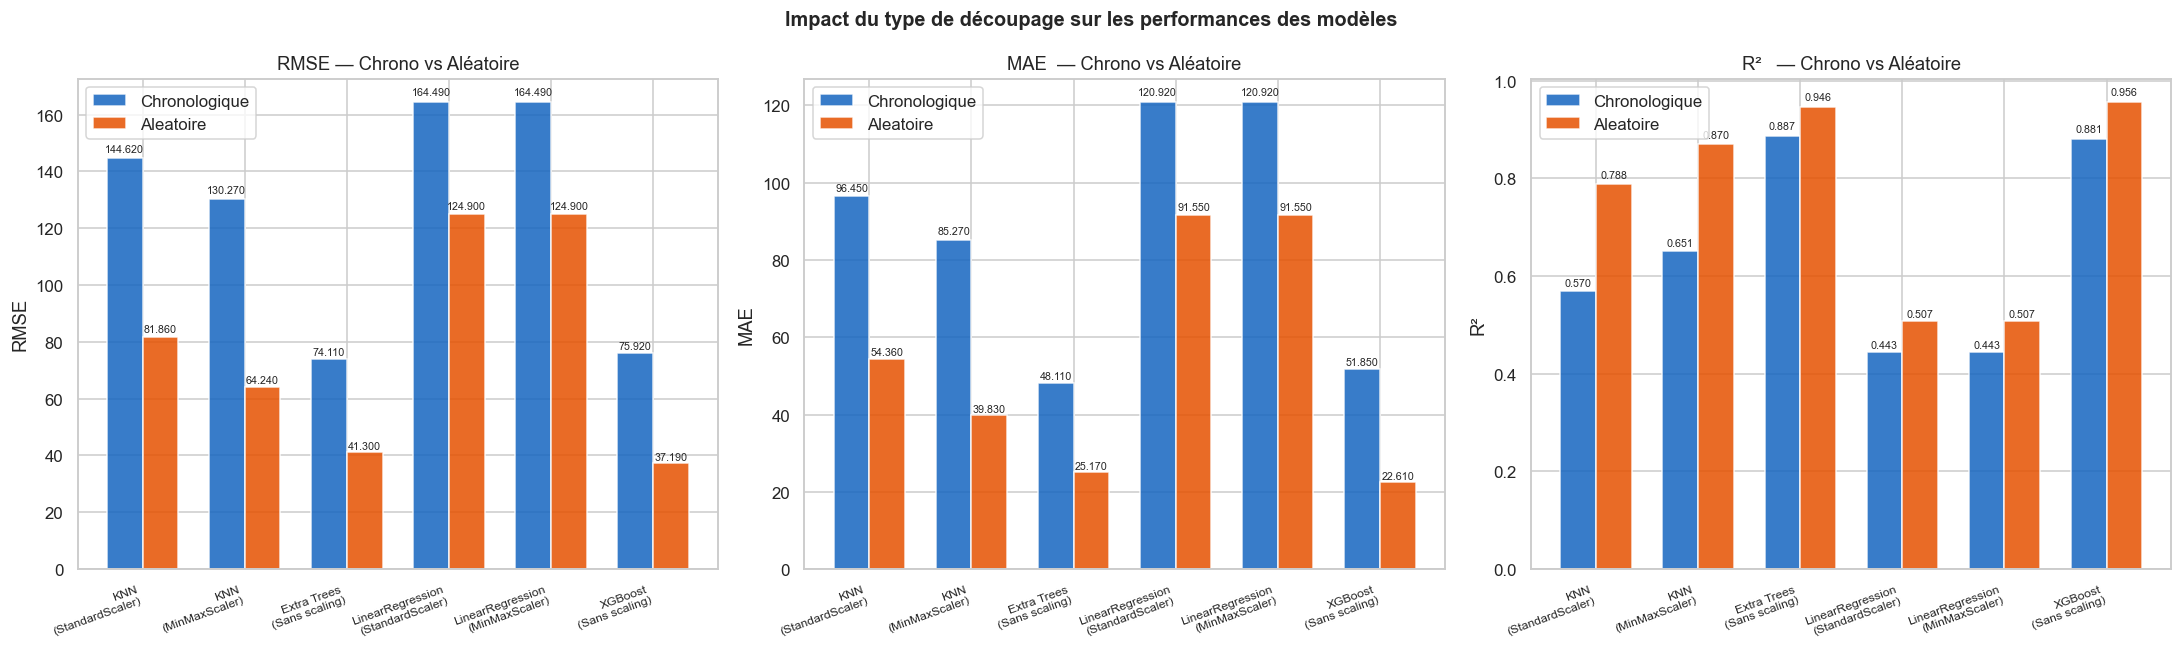

In [51]:
COLORS_CHRONO = "#1565C0"
COLORS_RAND   = "#E65100"

COLS_PALETTES = [
    "#1565C0", "#42A5F5",   # KNN
    "#2E7D32",              # Extra Trees
    "#6A1B9A", "#AB47BC",   # LinearRegression
    "#C62828",              # XGBoost
]

labels_models = [f"{r['Modele']}\n({r['Scaling']})" for r in rows_chrono]
x = list(range(len(labels_models)))
w = 0.35

# ── 1. RMSE comparatif chrono vs aléatoire ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

rmse_c = [r["RMSE"] for r in rows_chrono]
rmse_r = [r["RMSE"] for r in rows_rand]
mae_c  = [r["MAE"]  for r in rows_chrono]
mae_r  = [r["MAE"]  for r in rows_rand]
r2_c   = [r["R2"]   for r in rows_chrono]
r2_r   = [r["R2"]   for r in rows_rand]

def grouped_bars(ax, vals_c, vals_r, ylabel, title):
    bars1 = ax.bar(
        [i - w/2 for i in x], vals_c, w,
        label="Chronologique",
        color=COLORS_CHRONO, alpha=0.85, edgecolor="white"
    )

    bars2 = ax.bar(
        [i + w/2 for i in x], vals_r, w,
        label="Aleatoire",
        color=COLORS_RAND, alpha=0.85, edgecolor="white"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(labels_models, fontsize=8, rotation=20, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()

    # Afficher les valeurs horizontalement avec 3 chiffres après la virgule
    for bar, val in zip(bars1, vals_c):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() * 1.01,
            f"{val:.3f}",
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=0
        )
    
    for bar, val in zip(bars2, vals_r):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() * 1.01,
            f"{val:.3f}",
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=0
        )

grouped_bars(axes[0], rmse_c, rmse_r, "RMSE", "RMSE — Chrono vs Aléatoire")
grouped_bars(axes[1], mae_c,  mae_r,  "MAE",  "MAE  — Chrono vs Aléatoire")
grouped_bars(axes[2], r2_c,   r2_r,   "R²",   "R²   — Chrono vs Aléatoire")

plt.suptitle("Impact du type de découpage sur les performances des modèles",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

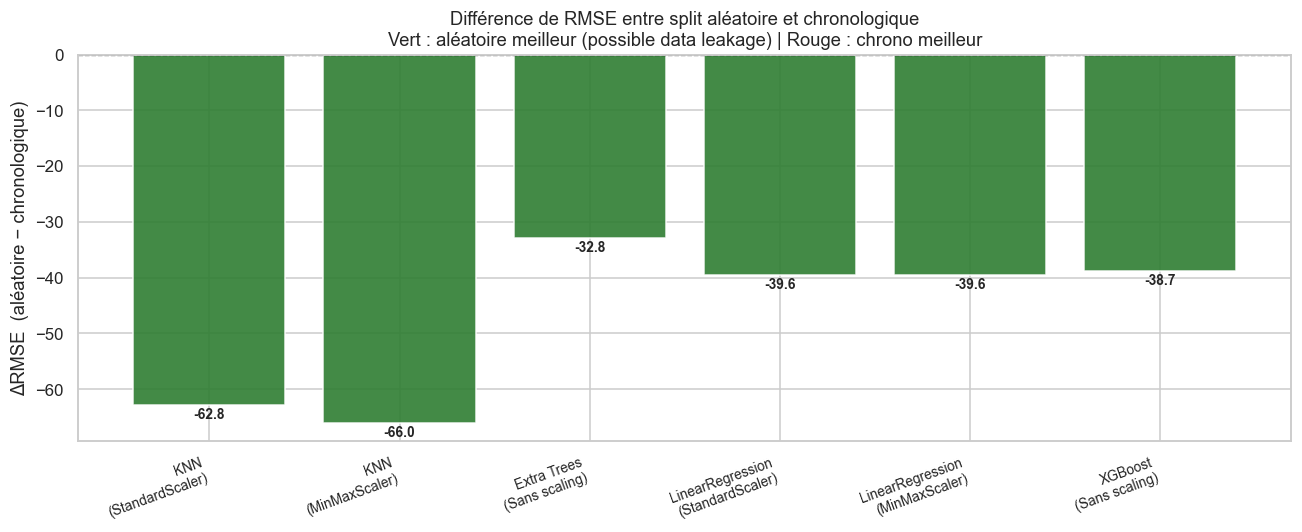

In [41]:
# ── 2. ΔRMSE : effet du split aléatoire par rapport au chrono ────────────────
delta_rmse = [r["ΔRMSE"] for r in cmp_rows]

fig, ax = plt.subplots(figsize=(12, 5))
colors_delta = ["#2E7D32" if d <= 0 else "#C62828" for d in delta_rmse]
bars = ax.bar(labels_models, delta_rmse, color=colors_delta, edgecolor="white", alpha=0.9)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_ylabel("ΔRMSE  (aléatoire − chronologique)")
ax.set_title("Différence de RMSE entre split aléatoire et chronologique\n"
             "Vert : aléatoire meilleur (possible data leakage) | Rouge : chrono meilleur")
ax.set_xticks(range(len(labels_models)))
ax.set_xticklabels(labels_models, fontsize=9, rotation=20, ha="right")
for bar, d in zip(bars, delta_rmse):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + (1 if d >= 0 else -3),
            f"{d:+.1f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

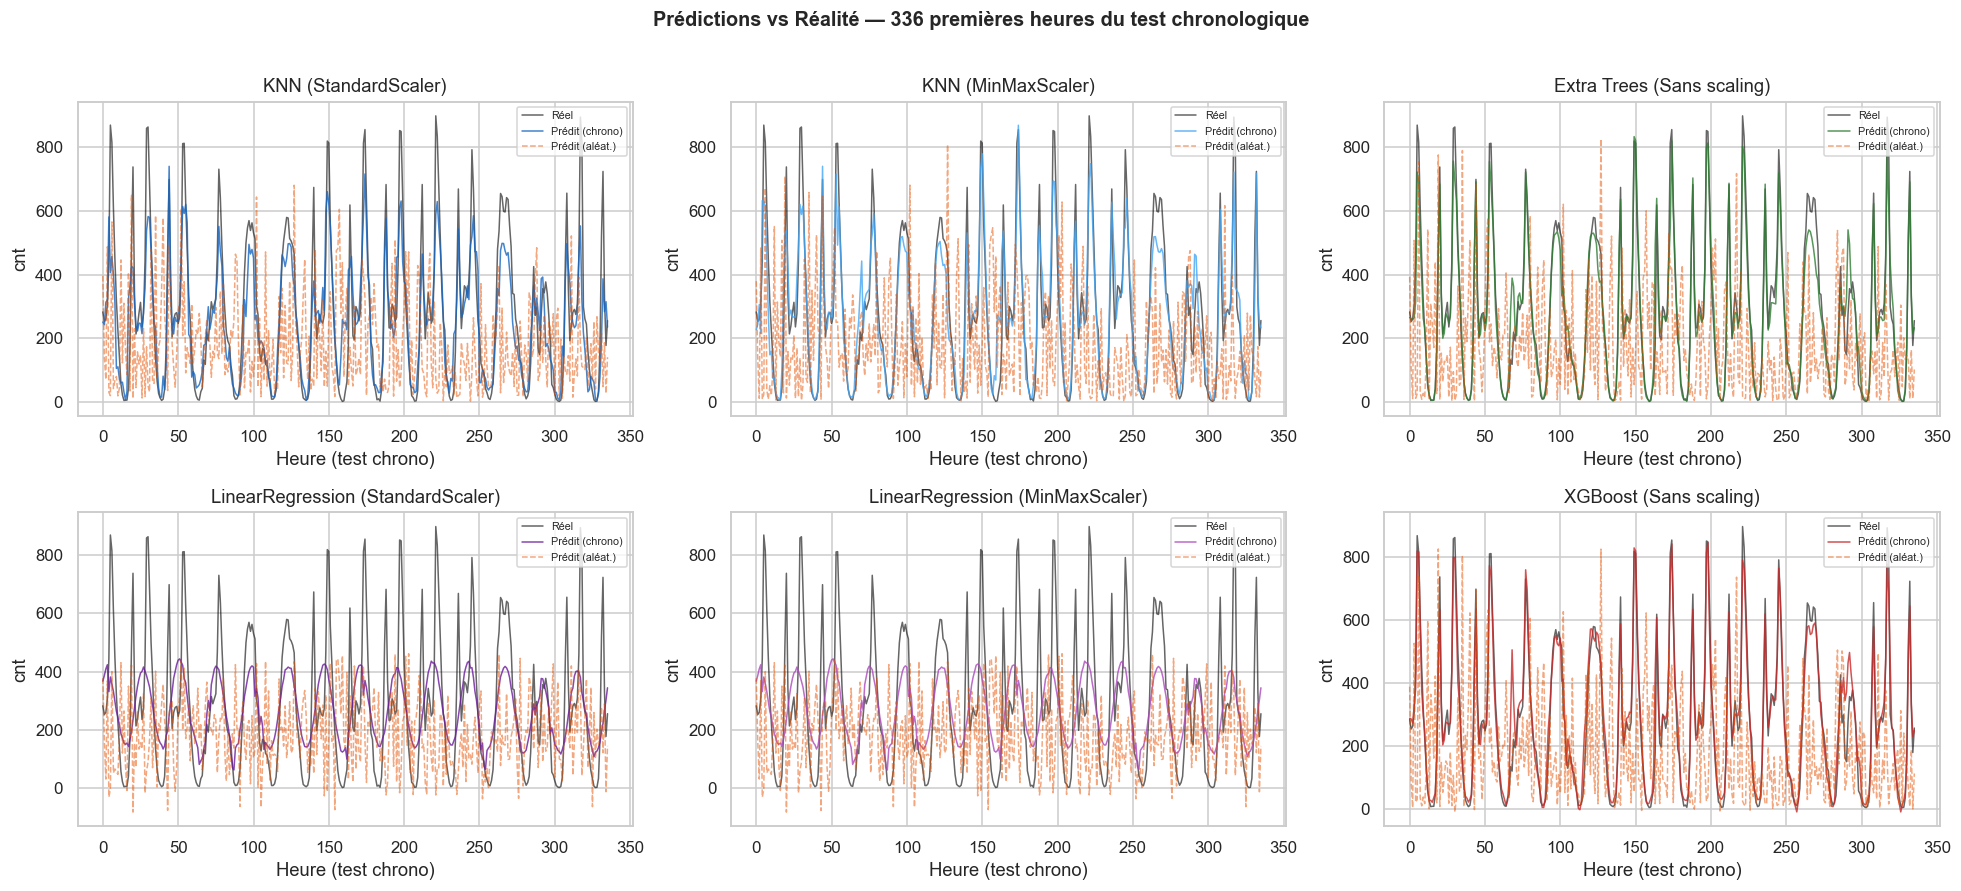

In [52]:
# ── 3. Valeurs réelles vs prédites (test chrono uniquement, modèles côte-à-côte) ─
N_DISP = min(336, len(y_test_chrono))
ncols = 3
nrows = (len(rows_chrono) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
axes_flat = axes.ravel() if nrows > 1 else axes

for idx, r in enumerate(rows_chrono):
    ax = axes_flat[idx]
    ax.plot(range(N_DISP), y_test_chrono.values[:N_DISP],
            label="Réel", color="black", alpha=0.6, linewidth=1)
    ax.plot(range(N_DISP), r["y_pred"][:N_DISP],
            label="Prédit (chrono)", color=COLS_PALETTES[idx % len(COLS_PALETTES)],
            alpha=0.8, linewidth=1)
    ax.plot(range(N_DISP), rows_rand[idx]["y_pred"][:N_DISP],
            label="Prédit (aléat.)", color=COLORS_RAND, alpha=0.5,
            linewidth=1, linestyle="--")
    ax.set_title(f"{r['Modele']} ({r['Scaling']})")
    ax.set_xlabel("Heure (test chrono)")
    ax.set_ylabel("cnt")
    ax.legend(fontsize=7)

for ax in axes_flat[len(rows_chrono):]:
    ax.set_visible(False)

plt.suptitle(f"Prédictions vs Réalité — {N_DISP} premières heures du test chronologique",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

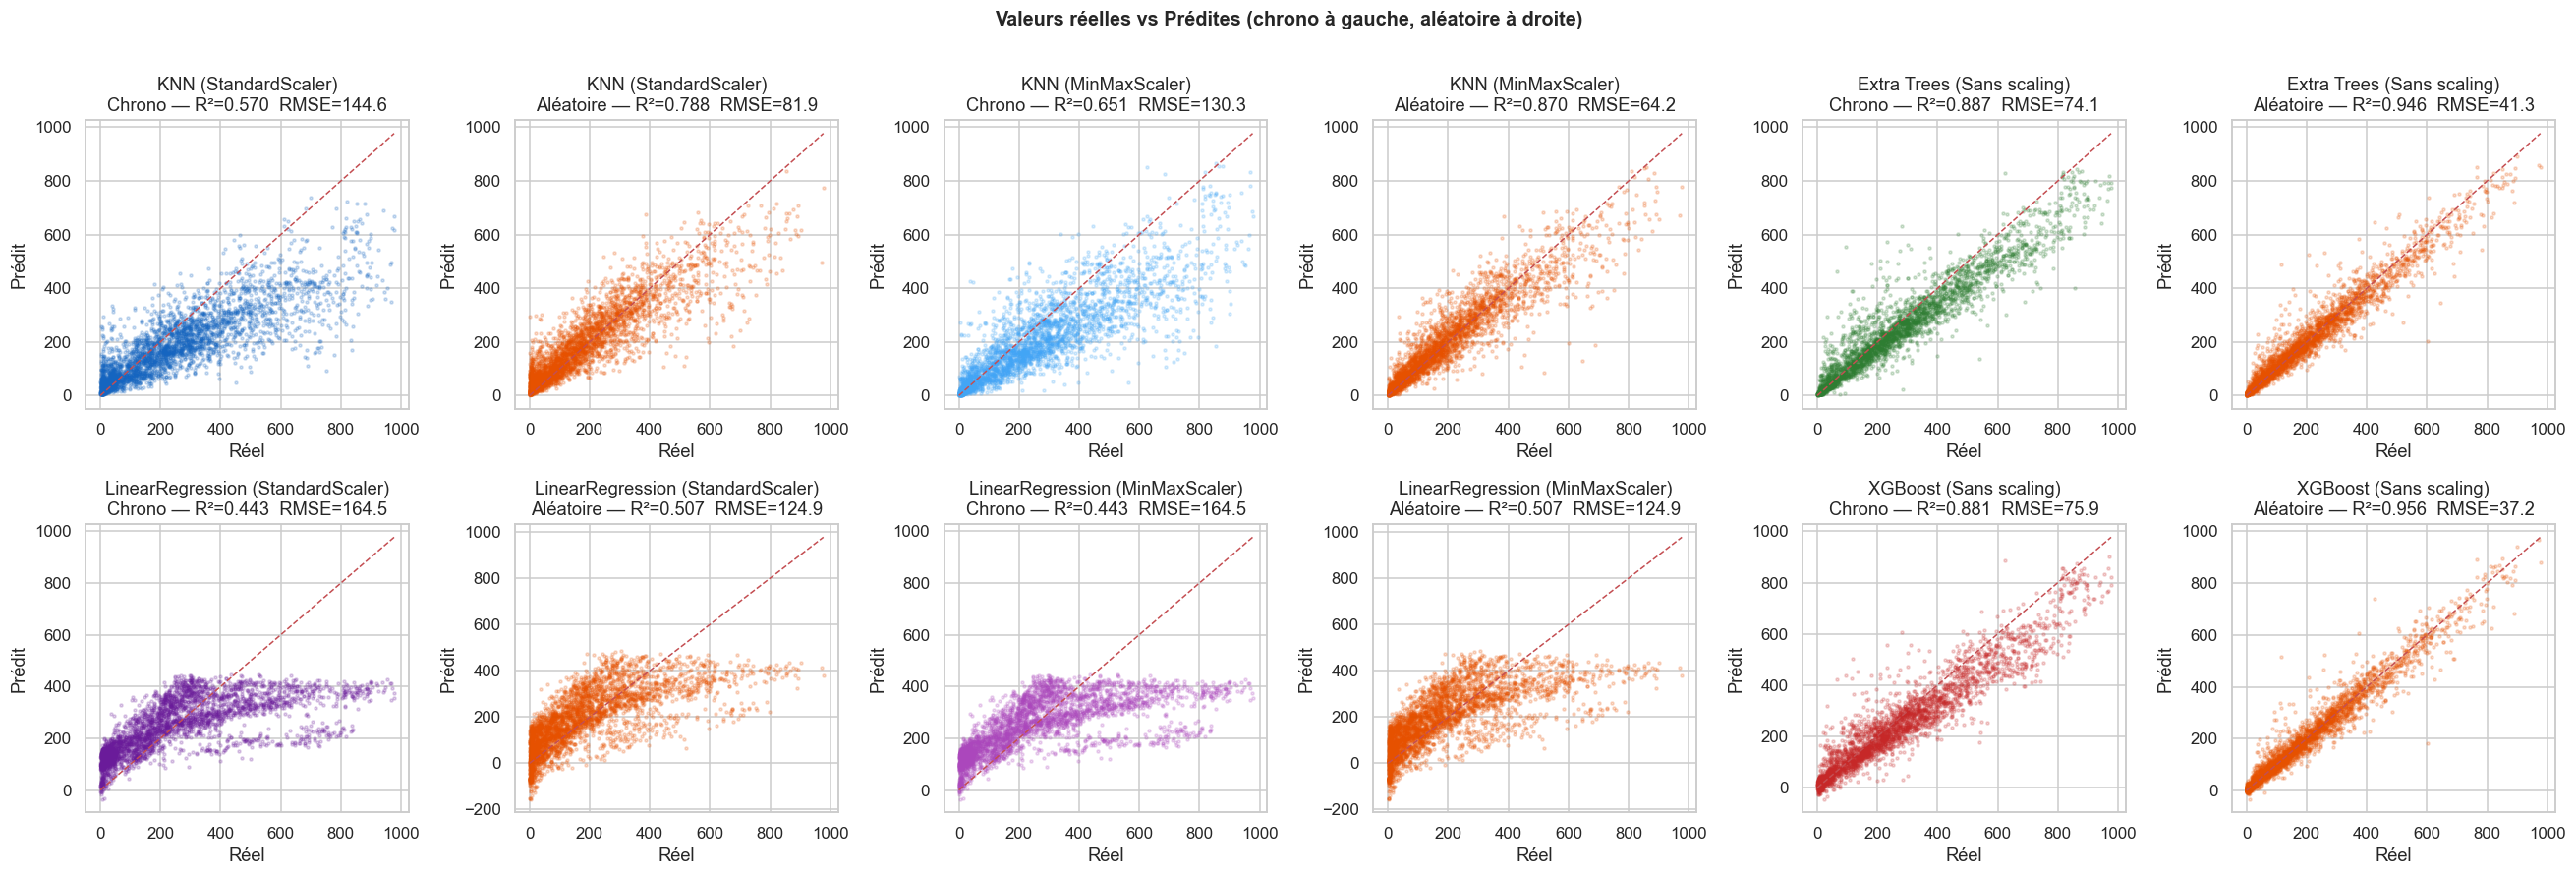

In [43]:
# ── 4. Scatter réel vs prédit pour les deux splits ────────────────────────────
fig, axes = plt.subplots(nrows, ncols * 2, figsize=(24, 4 * nrows))
axes_flat = axes.ravel()

for idx, (rc, rr) in enumerate(zip(rows_chrono, rows_rand)):
    # Chrono
    ax = axes_flat[idx * 2]
    max_v = max(y_test_chrono.max(), rc["y_pred"].max())
    ax.scatter(y_test_chrono, rc["y_pred"], alpha=0.2, s=4,
               color=COLS_PALETTES[idx % len(COLS_PALETTES)])
    ax.plot([0, max_v], [0, max_v], "r--", linewidth=1)
    ax.set_title(f"{rc['Modele']} ({rc['Scaling']})\nChrono — R²={rc['R2']:.3f}  RMSE={rc['RMSE']:.1f}")
    ax.set_xlabel("Réel"); ax.set_ylabel("Prédit")

    # Aléatoire
    ax = axes_flat[idx * 2 + 1]
    max_v = max(y_test_rand.max(), rr["y_pred"].max())
    ax.scatter(y_test_rand, rr["y_pred"], alpha=0.2, s=4, color=COLORS_RAND)
    ax.plot([0, max_v], [0, max_v], "r--", linewidth=1)
    ax.set_title(f"{rr['Modele']} ({rr['Scaling']})\nAléatoire — R²={rr['R2']:.3f}  RMSE={rr['RMSE']:.1f}")
    ax.set_xlabel("Réel"); ax.set_ylabel("Prédit")

for ax in axes_flat[len(rows_chrono) * 2:]:
    ax.set_visible(False)

plt.suptitle("Valeurs réelles vs Prédites (chrono à gauche, aléatoire à droite)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---
## 11. Analyse des résultats

### 11.1 Surapprentissage (Train vs Test) — les deux splits

In [44]:
print("=" * 80)
print("ANALYSE DU SURAPPRENTISSAGE (apres Grid Search)")
print("=" * 80)

for split_name, split_results in results_by_split.items():
    print(f"\n  Split : {split_name}")
    print(f"  {'Modele':15s}  {'Scaling':15s}  {'RMSE_train':>10}  {'RMSE_test':>10}  {'Ecart':>8}  Statut")
    print("  " + "-" * 65)
    for r in split_results:
        gap    = r["RMSE"] - r["RMSE_train"]
        status = "Sur-app. probable" if gap > 30 else "OK"
        print(f"  {r['Modele']:15s}  {r['Scaling']:15s}  "
              f"{r['RMSE_train']:10.2f}  {r['RMSE']:10.2f}  {gap:+8.2f}  {status}")

ANALYSE DU SURAPPRENTISSAGE (apres Grid Search)

  Split : Chronologique
  Modele           Scaling          RMSE_train   RMSE_test     Ecart  Statut
  -----------------------------------------------------------------
  KNN              StandardScaler         0.51      144.62   +144.11  Sur-app. probable
  KNN              MinMaxScaler           0.51      130.27   +129.76  Sur-app. probable
  Extra Trees      Sans scaling          26.75       74.11    +47.36  Sur-app. probable
  LinearRegression  StandardScaler       116.90      164.49    +47.59  Sur-app. probable
  LinearRegression  MinMaxScaler         116.90      164.49    +47.59  Sur-app. probable
  XGBoost          Sans scaling          32.32       75.92    +43.60  Sur-app. probable

  Split : Aleatoire
  Modele           Scaling          RMSE_train   RMSE_test     Ecart  Statut
  -----------------------------------------------------------------
  KNN              StandardScaler         0.60       81.86    +81.26  Sur-app. probabl

### 11.2 Courbes d'apprentissage du meilleur modèle (split chronologique)

Meilleur modele (chrono) : Extra Trees (Sans scaling)
RMSE test (chrono) = 74.11
Calcul des courbes d'apprentissage...


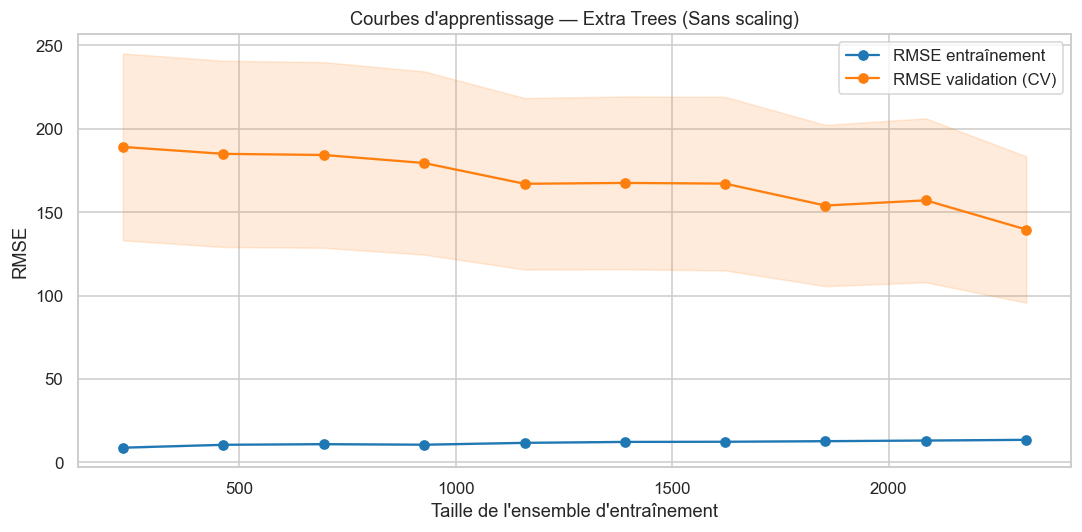

RMSE entraînement (100%) : 13.48
RMSE validation  (100%) : 139.56
Ecart train/val         : +126.07


In [53]:
best_r = min(results_by_split["Chronologique"], key=lambda r: r["RMSE"])
best_estimator = best_r["estimator"]

print(f"Meilleur modele (chrono) : {best_r['Modele']} ({best_r['Scaling']})")
print(f"RMSE test (chrono) = {best_r['RMSE']:.2f}")
print("Calcul des courbes d'apprentissage...")

train_sizes, train_scores, val_scores = learning_curve(
    best_estimator,
    X_train_chrono, y_train_chrono,
    train_sizes=[0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00],
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

tr_rmse = -train_scores.mean(axis=1)
va_rmse = -val_scores.mean(axis=1)
tr_std  =  train_scores.std(axis=1)
va_std  =  val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_sizes, tr_rmse, "o-", color="tab:blue",   label="RMSE entraînement")
ax.plot(train_sizes, va_rmse, "o-", color="tab:orange", label="RMSE validation (CV)")
ax.fill_between(train_sizes, tr_rmse - tr_std, tr_rmse + tr_std,
                alpha=0.15, color="tab:blue")
ax.fill_between(train_sizes, va_rmse - va_std, va_rmse + va_std,
                alpha=0.15, color="tab:orange")
ax.set_xlabel("Taille de l'ensemble d'entraînement")
ax.set_ylabel("RMSE")
ax.set_title(f"Courbes d'apprentissage — {best_r['Modele']} ({best_r['Scaling']})")
ax.legend()
plt.tight_layout()
plt.show()

print(f"RMSE entraînement (100%) : {tr_rmse[-1]:.2f}")
print(f"RMSE validation  (100%) : {va_rmse[-1]:.2f}")
print(f"Ecart train/val         : {va_rmse[-1] - tr_rmse[-1]:+.2f}")

---
## 12. Expérimentation : transformation log1p de la cible (split chronologique)

L'EDA a montré que `cnt` est asymétrique (skewness ≈ 1.28). Appliquer `log1p`
peut aider certains modèles (la régression linéaire notamment).

**Protocole :**
1. Entraîner chaque modèle optimisé sur `log1p(cnt)` — split **chronologique** uniquement
2. Reconvertir avec `np.expm1()` pour obtenir les prédictions sur l'échelle originale
3. Comparer les métriques avec les modèles entraînés directement sur `cnt`

In [46]:
y_train_log = np.log1p(y_train_chrono)

print(f"cnt    — skewness : {y_train_chrono.skew():.2f}")
print(f"log1p  — skewness : {y_train_log.skew():.2f}")
print()

log_results = []

configs = [
    ("KNN",         "StandardScaler", build_preprocessor(StandardScaler),
     KNeighborsRegressor(**{k.replace("model__",""):v
                            for k,v in results_by_split["Chronologique"][0]["best_params"].items()})),
    ("KNN",         "MinMaxScaler",   build_preprocessor(MinMaxScaler),
     KNeighborsRegressor(**{k.replace("model__",""):v
                            for k,v in results_by_split["Chronologique"][1]["best_params"].items()})),
    ("Extra Trees", "Sans scaling",   build_preprocessor(None),
     ExtraTreesRegressor(**{k.replace("model__",""):v
                            for k,v in results_by_split["Chronologique"][2]["best_params"].items()},
                         random_state=RANDOM_STATE, n_jobs=-1)),
    ("LinearRegression",       "StandardScaler", build_preprocessor(StandardScaler),
     LinearRegression()),
    ("LinearRegression",       "MinMaxScaler",   build_preprocessor(MinMaxScaler),
     LinearRegression()),
    ("XGBoost",     "Sans scaling",   build_preprocessor(None),
     XGBRegressor(**{k.replace("model__",""):v
                     for k,v in results_by_split["Chronologique"][5]["best_params"].items()},
                  random_state=RANDOM_STATE, n_jobs=-1,
                  eval_metric="rmse", verbosity=0)),
]

for modele, scaling, prep, estimator in configs:
    pipe = Pipeline([("preprocessor", prep), ("model", estimator)])
    pipe.fit(X_train_chrono, y_train_log)

    y_pred_log  = pipe.predict(X_test_chrono)
    y_pred_orig = np.maximum(np.expm1(y_pred_log), 0)

    rmse = mean_squared_error(y_test_chrono, y_pred_orig) ** 0.5
    mae  = mean_absolute_error(y_test_chrono, y_pred_orig)
    r2   = r2_score(y_test_chrono, y_pred_orig)

    log_results.append(dict(Modele=modele, Scaling=scaling,
                            RMSE_log=round(rmse, 2),
                            MAE_log=round(mae, 2),
                            R2_log=round(r2, 4)))
    print(f"  {modele:15s} ({scaling:15s}) → RMSE={rmse:.2f}  MAE={mae:.2f}  R²={r2:.4f}")

cnt    — skewness : 1.28
log1p  — skewness : -0.82

  KNN             (StandardScaler ) → RMSE=159.09  MAE=103.19  R²=0.4794
  KNN             (MinMaxScaler   ) → RMSE=135.26  MAE=87.70  R²=0.6237
  Extra Trees     (Sans scaling   ) → RMSE=74.52  MAE=46.79  R²=0.8858
  LinearRegression (StandardScaler ) → RMSE=187.01  MAE=125.84  R²=0.2806
  LinearRegression (MinMaxScaler   ) → RMSE=187.01  MAE=125.84  R²=0.2806
  XGBoost         (Sans scaling   ) → RMSE=66.75  MAE=42.09  R²=0.9083


Comparaison cnt vs log1p(cnt) — metriques test chrono (ΔRMSE < 0 : log1p ameliore)

          Modele        Scaling  RMSE_cnt  RMSE_log  ΔRMSE  R2_cnt  R2_log     ΔR2
             KNN StandardScaler    144.62    159.09  14.47  0.5697  0.4794 -0.0903
             KNN   MinMaxScaler    130.27    135.26   4.99  0.6509  0.6237 -0.0272
     Extra Trees   Sans scaling     74.11     74.52   0.41  0.8870  0.8858 -0.0012
LinearRegression StandardScaler    164.49    187.01  22.52  0.4434  0.2806 -0.1628
LinearRegression   MinMaxScaler    164.49    187.01  22.52  0.4434  0.2806 -0.1628
         XGBoost   Sans scaling     75.92     66.75  -9.17  0.8814  0.9083  0.0269


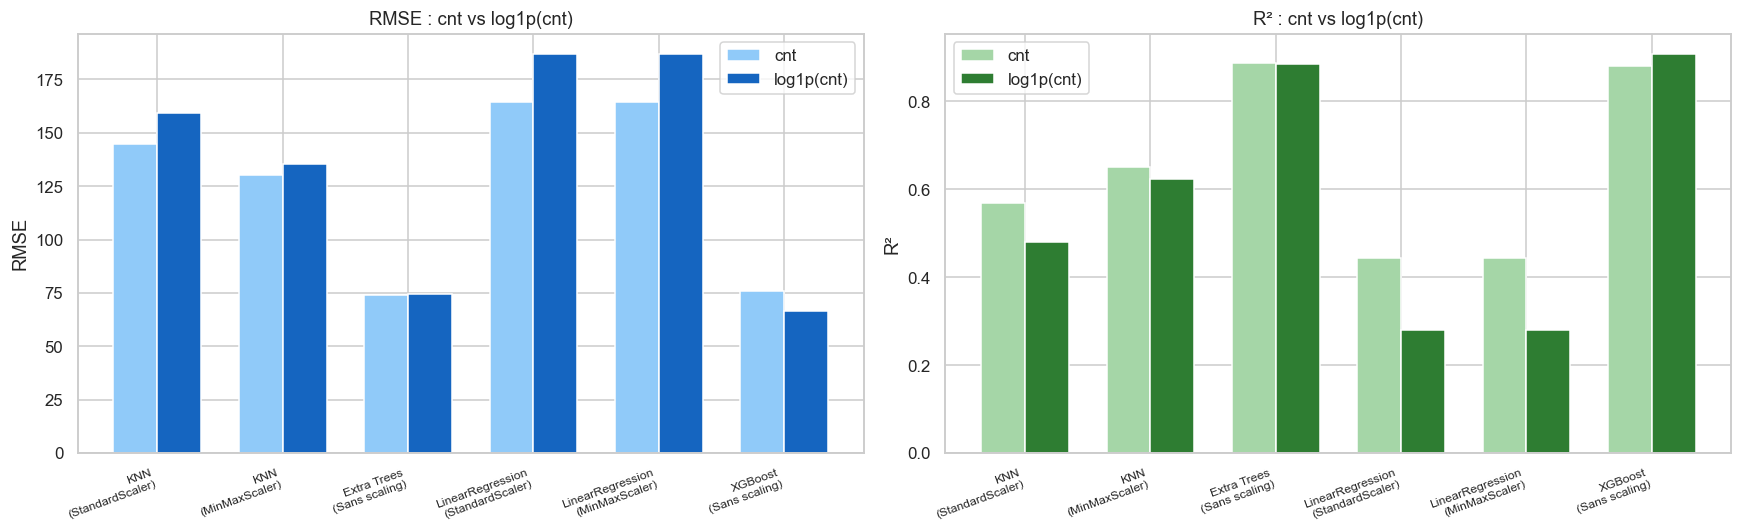

In [47]:
# Tableau comparatif cnt vs log1p (split chrono)
df_log = pd.DataFrame(log_results)
df_ref = pd.DataFrame([
    dict(Modele=r["Modele"], Scaling=r["Scaling"],
         RMSE_cnt=r["RMSE"], MAE_cnt=r["MAE"], R2_cnt=r["R2"])
    for r in results_by_split["Chronologique"]
])
df_cmp_log = df_ref.merge(df_log, on=["Modele", "Scaling"])
df_cmp_log["ΔRMSE"] = (df_cmp_log["RMSE_log"] - df_cmp_log["RMSE_cnt"]).round(2)
df_cmp_log["ΔR2"]   = (df_cmp_log["R2_log"]   - df_cmp_log["R2_cnt"]).round(4)

print("Comparaison cnt vs log1p(cnt) — metriques test chrono (ΔRMSE < 0 : log1p ameliore)")
print()
print(df_cmp_log[["Modele","Scaling","RMSE_cnt","RMSE_log","ΔRMSE","R2_cnt","R2_log","ΔR2"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
xlabels = [f"{r['Modele']}\n({r['Scaling']})" for r in results_by_split["Chronologique"]]
xpos = range(len(xlabels))
w = 0.35

axes[0].bar([i - w/2 for i in xpos], df_cmp_log["RMSE_cnt"], w,
            label="cnt", color="#90CAF9", edgecolor="white")
axes[0].bar([i + w/2 for i in xpos], df_cmp_log["RMSE_log"], w,
            label="log1p(cnt)", color="#1565C0", edgecolor="white")
axes[0].set_xticks(list(xpos)); axes[0].set_xticklabels(xlabels, fontsize=8, rotation=20, ha="right")
axes[0].set_ylabel("RMSE"); axes[0].set_title("RMSE : cnt vs log1p(cnt)"); axes[0].legend()

axes[1].bar([i - w/2 for i in xpos], df_cmp_log["R2_cnt"], w,
            label="cnt", color="#A5D6A7", edgecolor="white")
axes[1].bar([i + w/2 for i in xpos], df_cmp_log["R2_log"], w,
            label="log1p(cnt)", color="#2E7D32", edgecolor="white")
axes[1].set_xticks(list(xpos)); axes[1].set_xticklabels(xlabels, fontsize=8, rotation=20, ha="right")
axes[1].set_ylabel("R²"); axes[1].set_title("R² : cnt vs log1p(cnt)"); axes[1].legend()

plt.tight_layout(); plt.show()

---
## 13. Conclusion et prochaines étapes

### Ce que nous avons fait

1. **Feature engineering** : timestamp, variables cycliques (sin/cos), suppression de `atemp`
2. **Deux découpages testés** :
   - **Chronologique** (80/20 par ordre temporel) — méthode rigoureuse pour séries temporelles
   - **Aléatoire** (train_test_split, shuffle=True) — référence classique, possible data leakage
3. **Grid / Randomized Search** avec CV adapté à chaque type de split :
   - `TimeSeriesSplit(5)` pour le split chronologique
   - `KFold(5, shuffle=True)` pour le split aléatoire
4. **6 configurations × 2 splits** = 12 modèles optimisés comparés
5. **Analyse de l'impact du split** : quantification du data leakage temporel via ΔRMSE
6. **Expérimentation log1p** sur le split chronologique

### Prochaines étapes possibles

- **Stacking / Blending** : combiner les prédictions de plusieurs modèles optimisés
- **Feature engineering avancé** : lag features, variables d'interaction météo × heure
- **Modèles supplémentaires** : LightGBM, CatBoost, réseau de neurones
- **Interprétabilité** : SHAP values pour identifier les variables les plus influentes
- **Mise en production** : sauvegarder le meilleur pipeline avec `joblib`

---
## 14. Sauvegarde de tous les modèles entraînés

Cette section sauvegarde sur disque l'ensemble des pipelines entraînés (`ColumnTransformer` + modèle optimisé) pour les deux découpages (**Chronologique** et **Aléatoire**), ainsi que le fichier récapitulatif de toutes les métriques.


In [57]:
import joblib
from pathlib import Path
import pandas as pd

# ── Création du dossier 'models' à la racine ──────────────────────────────────
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

saved_models = []

# ── 1. Sauvegarde des pipelines (préprocesseur + modèle) ───────────────────────
if "results_by_split" in globals():
    for split_name, split_results in results_by_split.items():
        split_slug = "chrono" if "chrono" in split_name.lower() else "random"
        for r in split_results:
            model_slug = r["Modele"].lower().replace(" ", "_")
            scaling_slug = r["Scaling"].lower().replace(" ", "_")
            filename = f"model_{model_slug}_{scaling_slug}_{split_slug}.joblib"
            filepath = MODELS_DIR / filename
            
            # Sauvegarder le pipeline complet (préprocesseur ColumnTransformer + modèle)
            joblib.dump(r["estimator"], filepath)
            saved_models.append({
                "Fichier": filename,
                "Modèle": r["Modele"],
                "Scaling": r["Scaling"],
                "Découpage": split_name,
                "RMSE (Test)": r["RMSE"],
                "R² (Test)": r["R2"]
            })

    # ── 2. Sauvegarde du récapitulatif des métriques et hyperparamètres ───────────
    summary_path = MODELS_DIR / "summary_metrics_all_models.joblib"
    summary_dict = {
        split_name: [
            {k: v for k, v in r.items() if k not in ("estimator", "y_pred", "y_pred_train")}
            for r in split_results
        ]
        for split_name, split_results in results_by_split.items()
    }
    joblib.dump(summary_dict, summary_path)

print("=" * 95)
print(f"✅ TOUS LES MODÈLES ONT ÉTÉ SAUVEGARDÉS DANS : {MODELS_DIR.resolve()}")
print("=" * 95)
if saved_models:
    df_saved = pd.DataFrame(saved_models)
    print(df_saved.to_string(index=False))
print(f"\n📁 Fichier récapitulatif des métriques : {MODELS_DIR / 'summary_metrics_all_models.joblib'}")


✅ TOUS LES MODÈLES ONT ÉTÉ SAUVEGARDÉS DANS : C:\Users\isalm\Documents\master_insea\Saidi Nabil\Pr-vision-de-la-demande-de-v-los\models
                                            Fichier           Modèle        Scaling     Découpage  RMSE (Test)  R² (Test)
             model_knn_standardscaler_chrono.joblib              KNN StandardScaler Chronologique       144.62     0.5697
               model_knn_minmaxscaler_chrono.joblib              KNN   MinMaxScaler Chronologique       130.27     0.6509
       model_extra_trees_sans_scaling_chrono.joblib      Extra Trees   Sans scaling Chronologique        74.11     0.8870
model_linearregression_standardscaler_chrono.joblib LinearRegression StandardScaler Chronologique       164.49     0.4434
  model_linearregression_minmaxscaler_chrono.joblib LinearRegression   MinMaxScaler Chronologique       164.49     0.4434
           model_xgboost_sans_scaling_chrono.joblib          XGBoost   Sans scaling Chronologique        75.92     0.8814
          